# 01 · Data acquisition, cleaning and EDA
UCI Heart Disease, **Cleveland** subset (303 patients, 13 attributes + diagnosis).

Pipeline: download → validate/clean → explore. All logic lives in `src/heartml`, so this notebook, the scripts and CI run exactly the same code.

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))
os.environ["HEARTML_ROOT"] = str(ROOT)
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
pd.set_option("display.width", 140)

## 1. Download
`download_raw()` tries the official UCI file first and falls back to a GitHub mirror of the same 303 records (converted to UCI codes). The raw CSV is cached in `data/raw/`.

In [2]:
from heartml import config
from heartml.data import download_raw, clean
raw = pd.read_csv(config.RAW_DATA_PATH) if config.RAW_DATA_PATH.exists() else download_raw()
print(raw.shape); raw.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


## 2. Data quality checks

In [3]:
print("dtypes:", dict(raw.dtypes.astype(str)))
print("\nmissing values:\n", raw.isna().sum()[raw.isna().sum() > 0])
print("\nduplicate rows:", raw.duplicated().sum())
raw.describe().T.round(2)

dtypes: {'age': 'int64', 'sex': 'int64', 'cp': 'int64', 'trestbps': 'int64', 'chol': 'int64', 'fbs': 'int64', 'restecg': 'int64', 'thalach': 'int64', 'exang': 'int64', 'oldpeak': 'float64', 'slope': 'int64', 'ca': 'float64', 'thal': 'float64', 'num': 'int64'}

missing values:
 ca      4
thal    2
dtype: int64

duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


**Findings**
- Only 6 missing cells: `ca` (4) and `thal` (2) – originally `?` in the UCI file.
- No duplicates; all values sit within plausible clinical ranges.
- `num` is 0–4 (severity). The task is binary, so `target = num > 0`.

**Cleaning decisions** (`heartml.data.clean`): coerce to numeric, out-of-range values and unknown category codes → NaN, drop duplicates / unlabeled rows, binarise target. Missing values are **not** filled here; they are imputed inside the sklearn pipeline (median / mode) so training and serving share one code path and CV folds don't leak statistics.

In [4]:
df = clean(raw)
print(df.shape); df[config.TARGET].value_counts()

(303, 14)


target
0    164
1    139
Name: count, dtype: int64

## 3. Visual EDA
All figures are written to `reports/figures/eda/` and reused in the report.

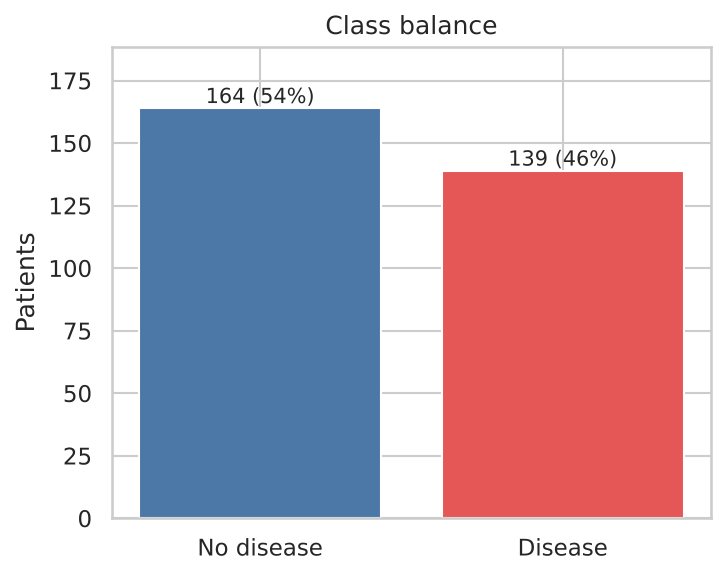

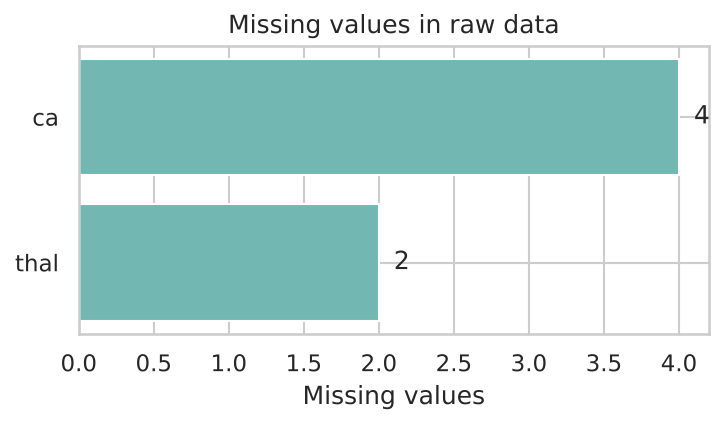

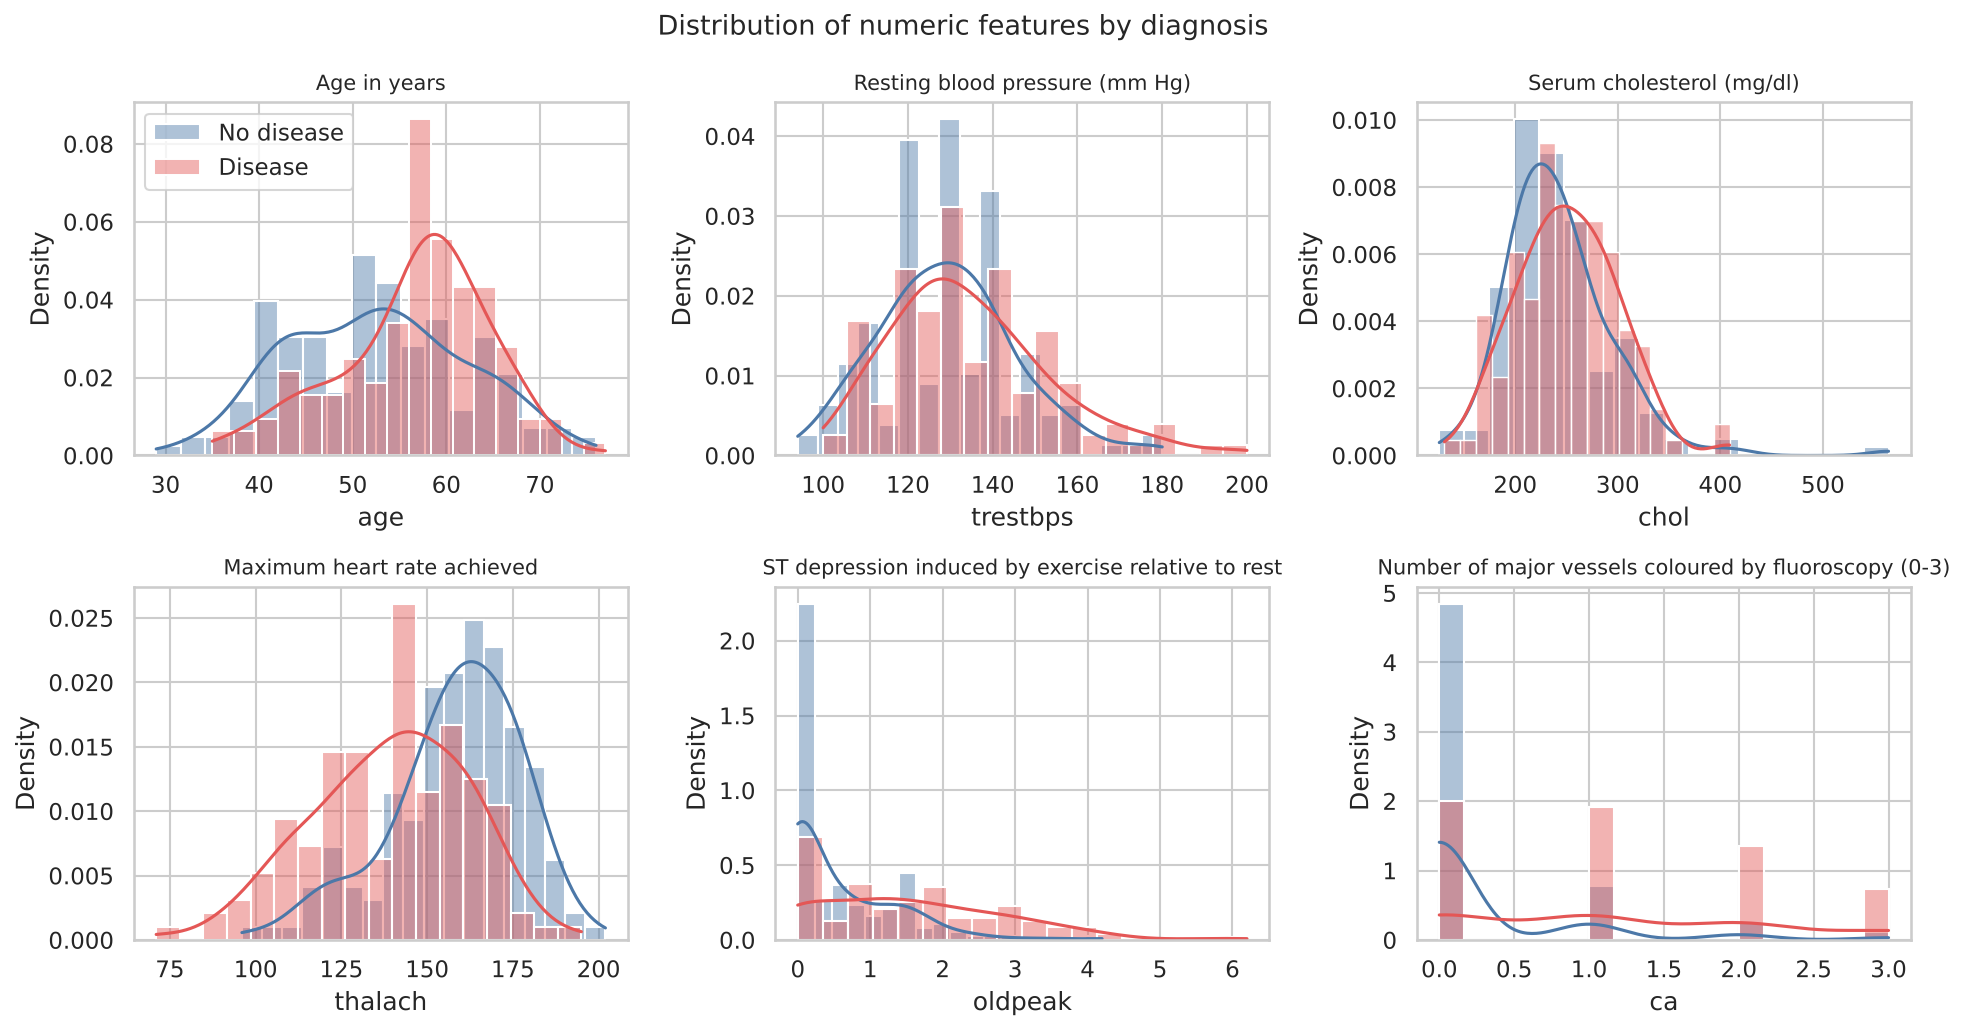

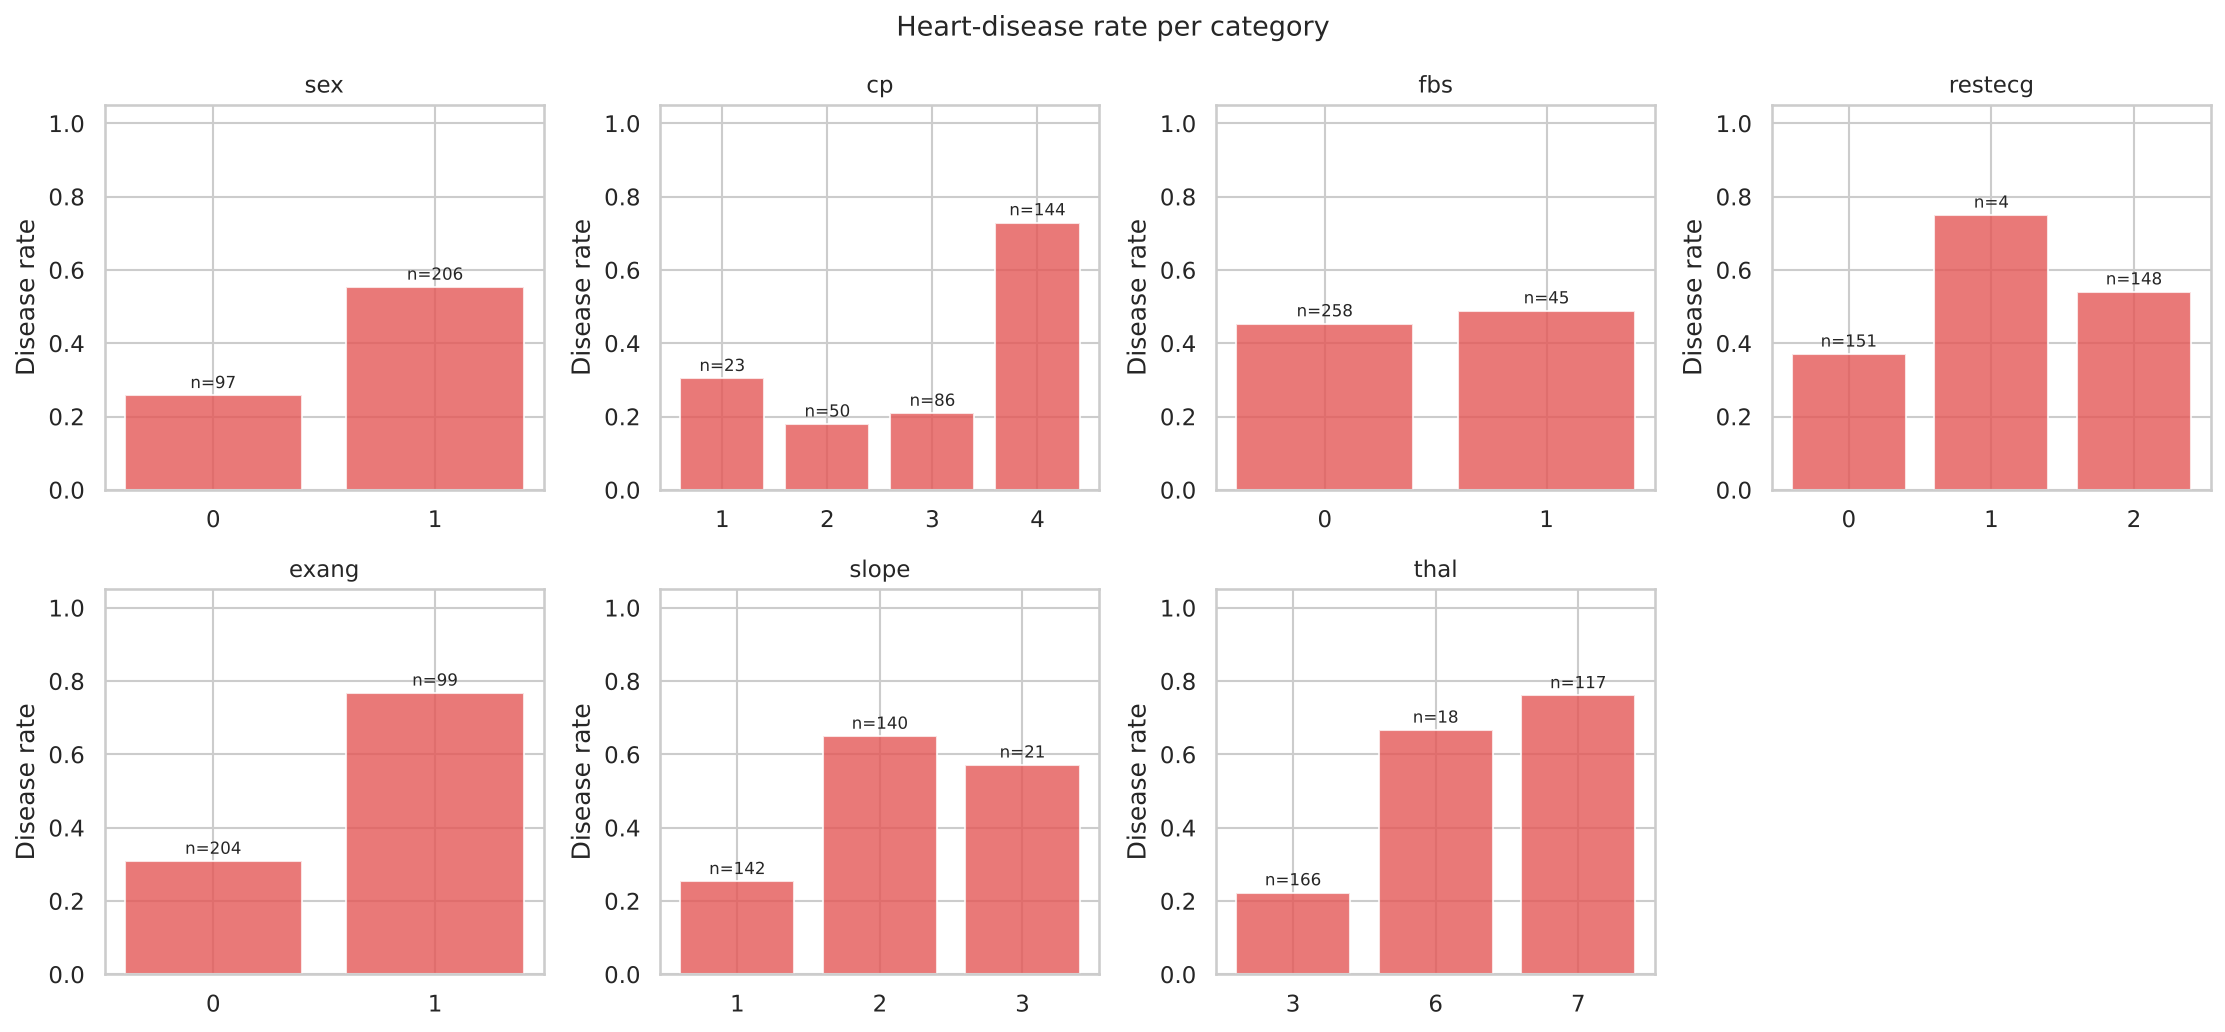

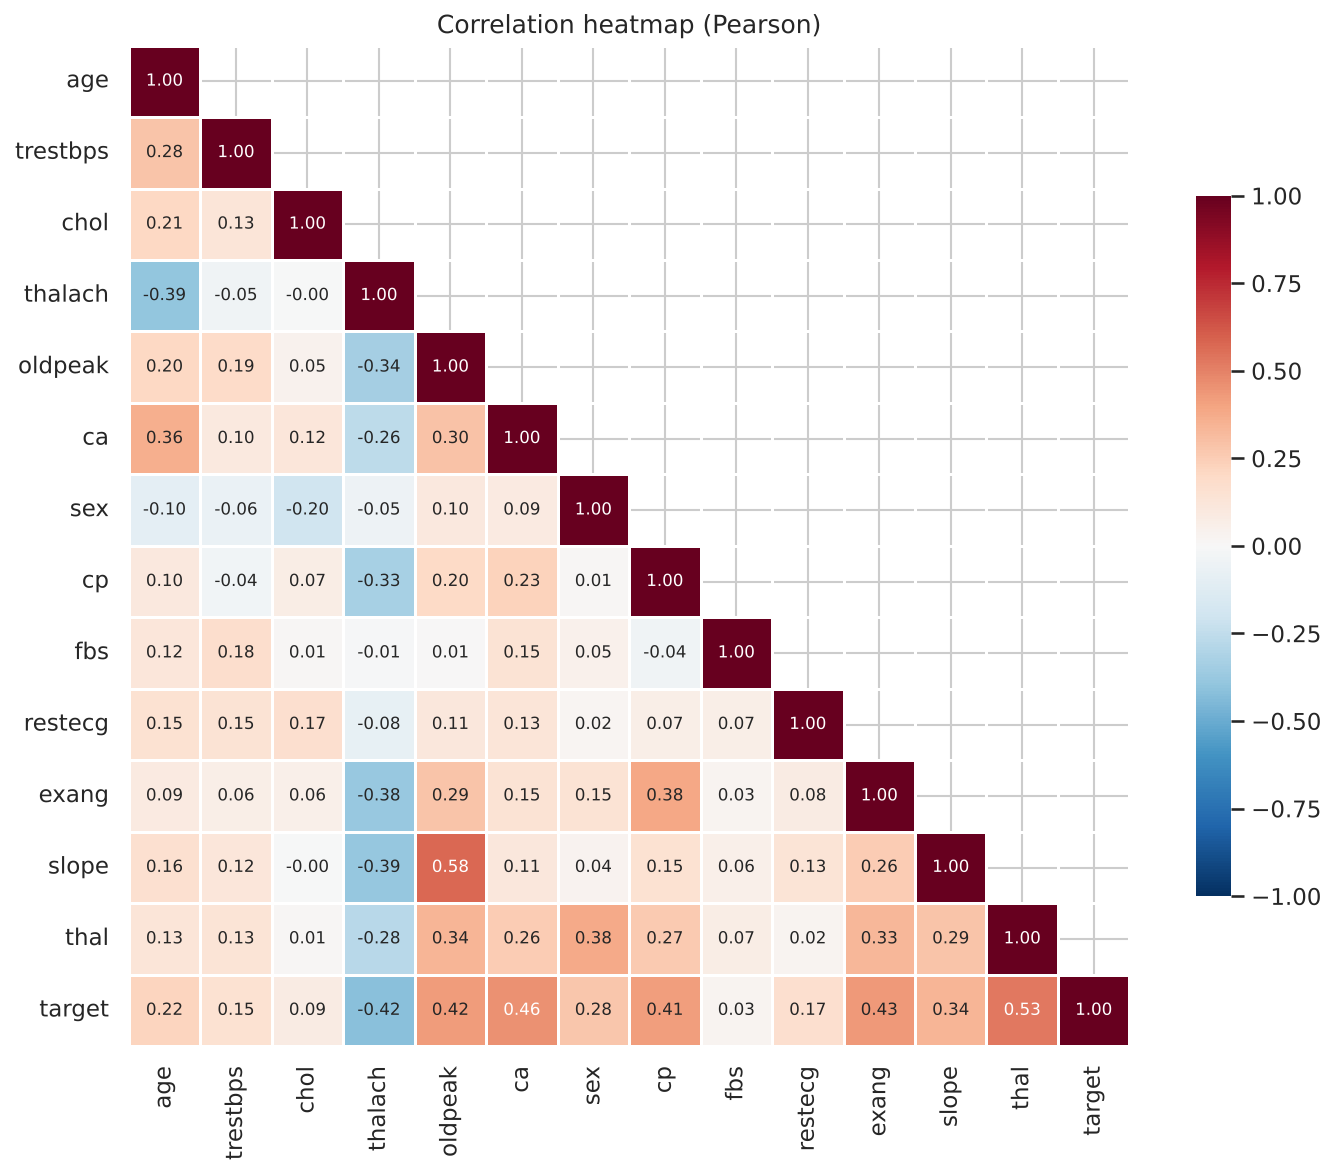

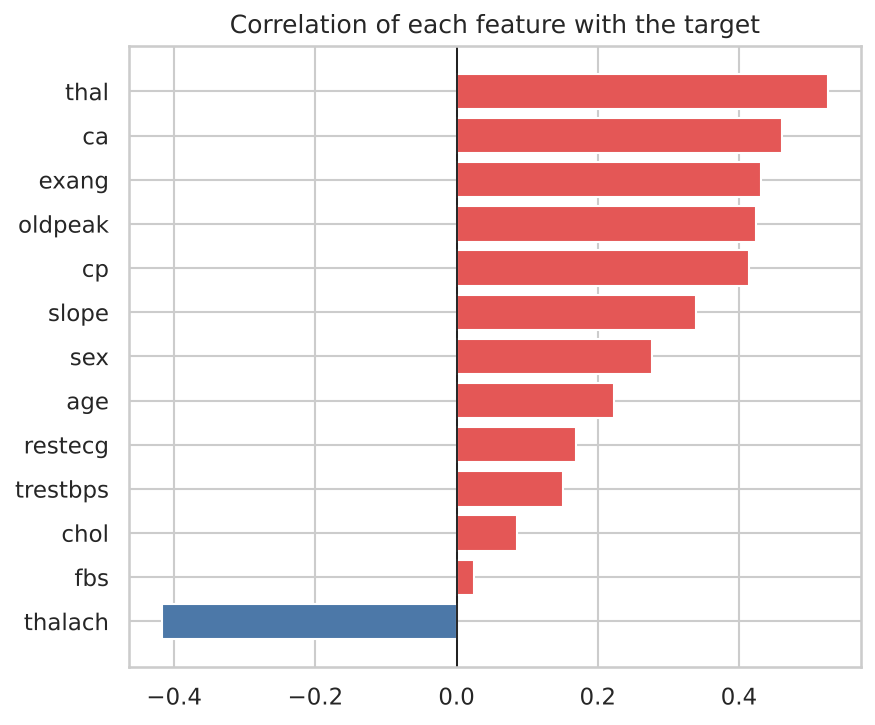

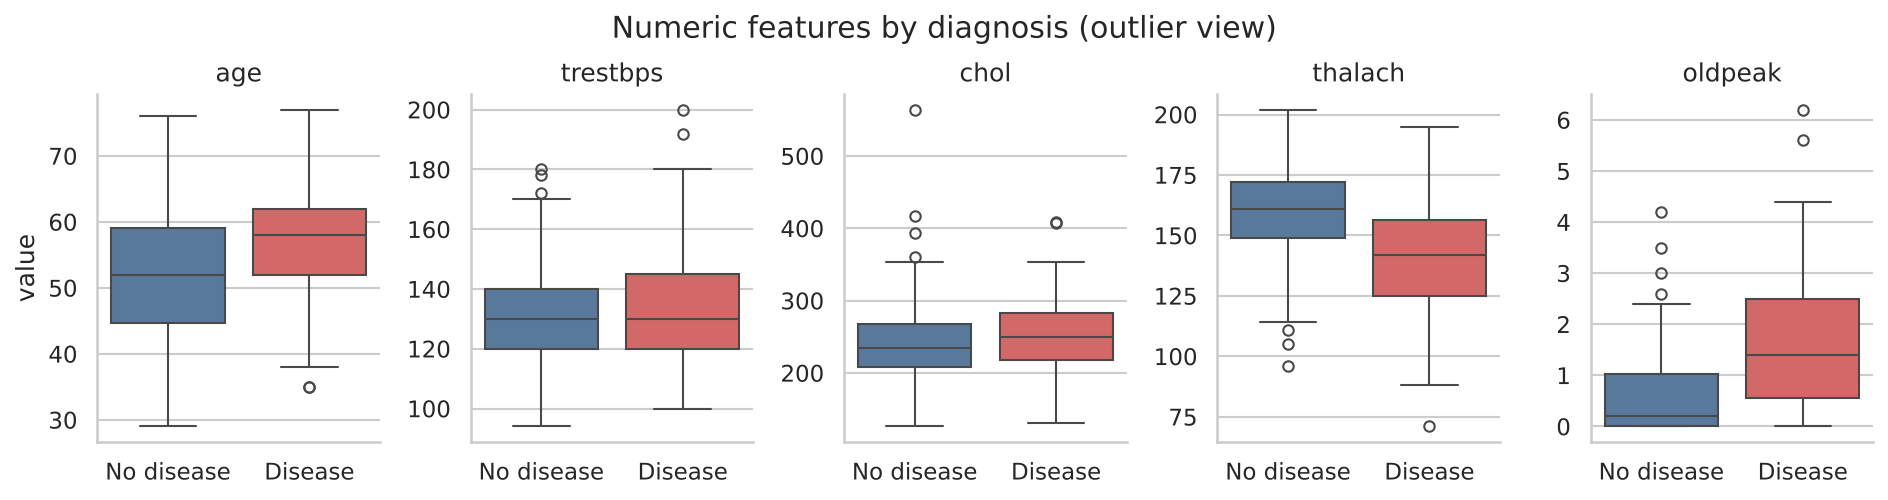

In [5]:
from heartml.eda import run_eda
from IPython.display import Image, display
summary = run_eda(raw, df)
for f in summary["figures"]:
    display(Image(filename=str(ROOT / f), width=820))

## 4. Takeaways that drive modelling
- **Balanced classes** (54 % / 46 %) → no resampling needed; ROC-AUC is a fair selection metric, and `class_weight='balanced'` is still tried in the grid.
- **Strongest signals:** `thal`, `ca`, `exang`, `oldpeak`, `thalach` (negative), `cp=4` (asymptomatic chest pain).
- `cp`, `thal`, `restecg`, `slope` are **nominal codes**, not ordinal → one-hot encode.
- Numeric features are on very different scales (chol ≈ 250 vs oldpeak ≈ 1) → standardise (required for regularised Logistic Regression).
- Weak features (`fbs`, `chol`) are kept: L1/L2 regularisation decides, rather than hand-pruning on 303 rows.
- `restecg = 1` has only 4 patients → `handle_unknown='ignore'` keeps rare/unseen codes safe.

In [6]:
df.to_csv(config.CLEAN_DATA_PATH, index=False)
print("saved", config.CLEAN_DATA_PATH.relative_to(ROOT))

saved data/processed/heart_clean.csv
